# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
from pathlib import Path

import matplotlib.pyplot as plt


class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]
    def bajar(self, i):
        A = self.arreglo
        while 2 * i < len(A):
            h = 2 * i
            if h + 1 < len(A) and A[h + 1] < A[h]:
                h += 1
            if A[h] >= A[i]:
                break
            A[i], A[h] = A[h], A[i]
            i = h

    def insert(self, valor, imagen=False):
        A = self.arreglo
        A.append(valor)
        i = len(A) - 1
        while A[i // 2] > A[i]:          # el -inf de A[0] lo detiene solo
            A[i], A[i // 2] = A[i // 2], A[i]
            i = i // 2
        if imagen: self.dibujar()

    def remove_smallest(self, imagen=False):
        A = self.arreglo
        menor = A[1]
        A[1] = A[-1]
        A.pop()
        self.bajar(1)
        if imagen: self.dibujar()
        return menor

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        for i in range(len(lista) // 2, 0, -1):
            self.bajar(i)
        if imagen: self.dibujar()

    def dibujar(self):
        A = self.arreglo
        pos = lambda i: ((i - 2**(i.bit_length()-1) + 0.5) / 2**(i.bit_length()-1), -i.bit_length())
        plt.figure(figsize=(10, 5))
        for i in range(1, len(A)):
            x, y = pos(i)
            if i > 1:                     # línea hacia el padre
                px, py = pos(i // 2)
                plt.plot([x, px], [y, py], 'k-')
            plt.text(x, y, A[i], ha='center', va='center',
                     bbox=dict(boxstyle='circle', fc='lightblue'))
        plt.axis('off')
        fotos_dir = Path(__file__).parent / "fotos"
        fotos_dir.mkdir(exist_ok=True)
        numero = 1
        archivo = fotos_dir / f"heap_{numero:03}.png"
        while archivo.exists():
            numero += 1
            archivo = fotos_dir / f"heap_{numero:03}.png"
        plt.savefig(archivo, bbox_inches='tight')
        plt.show()

Overwriting heap.py


In [2]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

NameError: name 'plt' is not defined

## 6. Prueba: 5 inserciones con fotos

Todos hacen **la misma prueba**: empezando con un heap vacío, inserte **en este orden** los valores

```python
[15, 8, 20, 3, 10]
```

con `imagen=True` en cada inserción, y guarde las **5 imágenes** (una después de cada inserción) como archivos PNG en la carpeta `fotos`, dentro de `student_work/Proyecto2`:

```
student_work/Proyecto2/
├── heap.py
└── fotos/
    ├── insert_1.png    # después de insertar 15
    ├── insert_2.png    # después de insertar 8
    ├── insert_3.png    # después de insertar 20
    ├── insert_4.png    # después de insertar 3
    └── insert_5.png    # después de insertar 10
```

- Use exactamente esos nombres de archivo y esa carpeta.
- Cada foto muestra el árbol del heap **completo** después de esa inserción.
- No olvide hacer *commit* y *push* de la carpeta `fotos`.

In [4]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)     # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]            # NO cambie esta lista


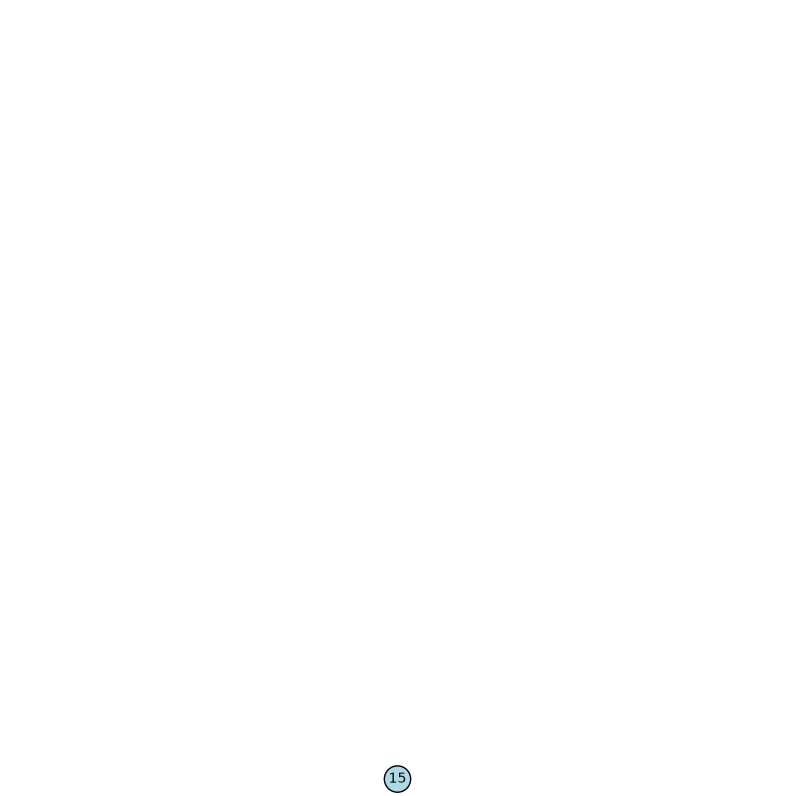

1 [-inf, 15]


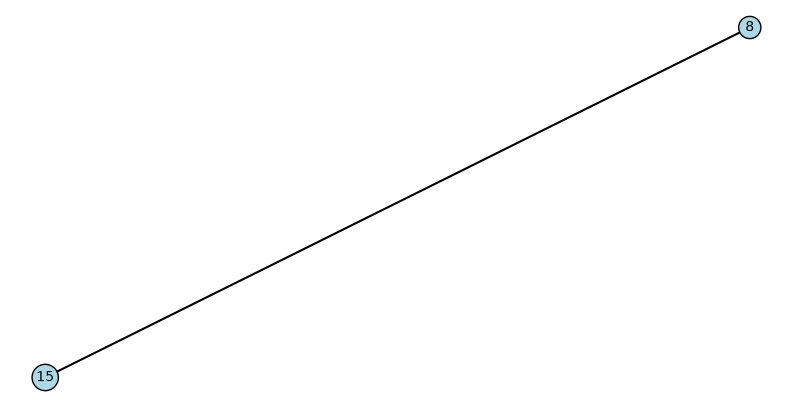

2 [-inf, 8, 15]


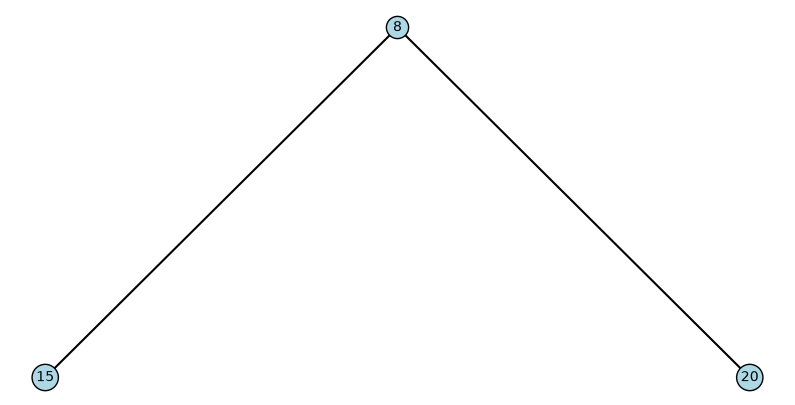

3 [-inf, 8, 15, 20]


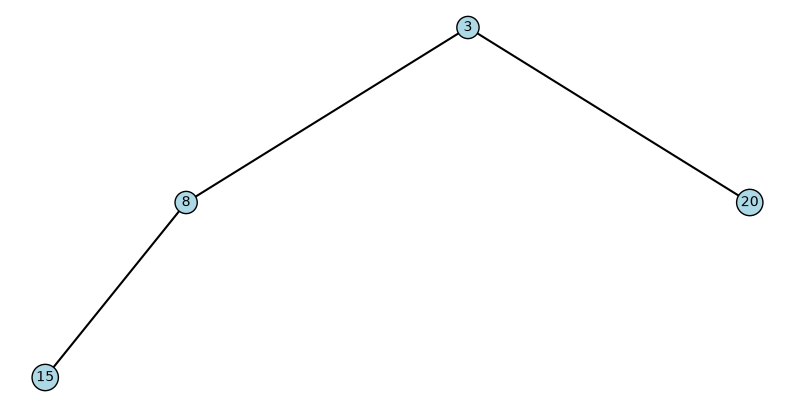

4 [-inf, 3, 8, 20, 15]


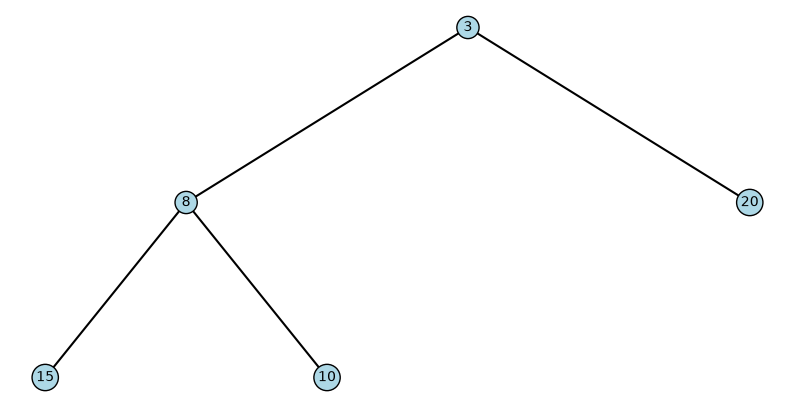

5 [-inf, 3, 8, 20, 15, 10]


In [5]:

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    print(i, H.arreglo)